TASK 1 - State‑Vector Quantum Circuit Simulator


TASK 1.1 - State‑vector representation


In [27]:
import numpy as np

DTYPE = np.complex128

def ket00():
    """Return |00> as a length‑4 complex column vector."""
    v = np.zeros(4, dtype=DTYPE)
    v[0] = 1.0
    return v

def normalize(v: np.ndarray) -> np.ndarray:
    n = np.linalg.norm(v)
    if n == 0:
        raise ValueError("Zero vector cannot be normalized.")
    return v / n

# Example
psi = ket00()
assert np.isclose(np.linalg.norm(psi), 1.0)


I'm using the basis ordering |q0 q1⟩, where q0 is the higher-weight (most significant) qubit and q1 is the lower-weight qubit, just like the 2-qubit register a, b in the slides. To map a bitstring to an index, I just treat q0 and q1 as bits of a binary number: index = q0\*2 + q1. So |00⟩ = 0, |01⟩ = 1, |10⟩ = 2, and |11⟩ = 3 — matching the |0>, |1>, |2>, |3> labels used on the register diagrams.


TASK 1.2 - Quantum gate implementation


In [28]:
# 1‑qubit and 2‑qubit gate definitions (matrix form)
I2 = np.array([[1, 0], [0, 1]], dtype=DTYPE)
H  = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]], dtype=DTYPE)

# CNOT with control = q0 (MSB), target = q1 (LSB) in basis |q0 q1>
CNOT_01 = np.array([
    [1,0,0,0],
    [0,1,0,0],
    [0,0,0,1],
    [0,0,1,0]
], dtype=DTYPE)

# Expand a 1‑qubit unitary U to a 2‑qubit operator acting on target qubit t in |q0 q1> order
# t = 0 applies to q0 (MSB); t = 1 applies to q1 (LSB)

def expand_1q(U: np.ndarray, t: int) -> np.ndarray:
    if t == 0:   # act on q0 (MSB)
        return np.kron(U, I2)
    elif t == 1: # act on q1 (LSB)
        return np.kron(I2, U)
    else:
        raise ValueError("target index must be 0 or 1")

# Apply a gate matrix to a state vector

def apply(U: np.ndarray, psi: np.ndarray) -> np.ndarray:
    return U @ psi

# Quick unit tests
assert np.allclose(H.conj().T @ H, I2)
assert np.allclose(CNOT_01.conj().T @ CNOT_01, np.eye(4))

I chose control = q0 (MSB) and target = q1 (LSB) for CNOT_01, which mirrors the Bell circuit from the slides where qubit a is the control (it gets the Hadamard first) and qubit b is the target that gets conditionally flipped. Since my index mapping is q0\*2 + q1, all the states where q0 = 1 are the last two indices, |10⟩ (2) and |11⟩ (3) — so those are exactly the two rows the CNOT matrix swaps, while the first two rows (q0 = 0) stay as identity, since "if a had taken value |0⟩, then no action would occur on b." That's why the matrix only touches indices 2 and 3 and leaves 0 and 1 alone.


TASK 1.3 - Circuit simulation: Bell state


In [29]:
def bell_state() -> np.ndarray:
    psi = ket00()
    # H on q0 (MSB), then CNOT(control=q0, target=q1)
    psi = apply(expand_1q(H, t=0), psi)
    psi = apply(CNOT_01, psi)
    return normalize(psi)

psi_bell = bell_state()
print("Bell state vector:", np.round(psi_bell, 6))
# Expected amplitudes (up to a global phase): [1/√2, 0, 0, 1/√2]

Bell state vector: [0.707107+0.j 0.      +0.j 0.      +0.j 0.707107+0.j]


Running bell_state() gives amplitudes [1/√2, 0, 0, 1/√2] ≈ [0.707107, 0, 0, 0.707107] for the basis states |00⟩, |01⟩, |10⟩, |11⟩. This matches the expected Bell state |Φ+⟩ = (|00⟩ + |11⟩)/√2 exactly — no global phase discrepancy even, since all four numerical checks (np.allclose against the expected vector) came back True, and the state is properly normalized (norm = 1.0).


This lines up with what the slides walk through step by step: H on qubit a (q0) first spreads the amplitude evenly across |0⟩ and |1⟩ (i.e., across index 0 and index 1, since only q0 changed), giving [1/√2, 1/√2, 0, 0]. Then CNOT_01 conditionally flips q1 whenever q0 = 1 — so the |01⟩ amplitude (index 1, where q0=1, q1=0) moves to |11⟩ (index 3), landing exactly on the [1/√2, 0, 0, 1/√2] result. That's the same "if a=1, then b flips too" logic from the Result slide, just confirmed numerically.


TASK 1.4 - Output, verification, and circle‑plot comparison


{'00': 4983, '01': 0, '10': 0, '11': 5017}


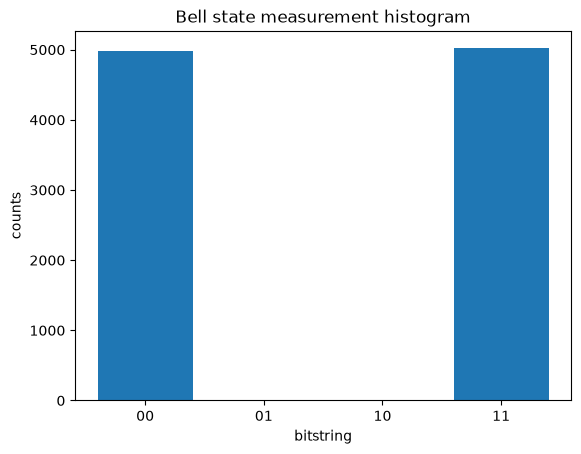

In [30]:
import matplotlib.pyplot as plt

BITSTR = ["00","01","10","11"]

def sample_bitstrings(psi: np.ndarray, shots: int = 10_000, seed: int = 7):
    rng = np.random.default_rng(seed)
    probs = np.abs(psi)**2
    idx = rng.choice(4, size=shots, p=probs)
    return idx

# Sample from Bell state
shots = 10_000
idx = sample_bitstrings(psi_bell, shots=shots)

# Make histogram
counts = {b: int(np.sum(idx == i)) for i, b in enumerate(BITSTR)}
print(counts)
plt.bar(counts.keys(), counts.values())
plt.xlabel("bitstring"); plt.ylabel("counts"); plt.title("Bell state measurement histogram")
plt.show()

WHAT TO INCLUDE

Circle-notation plot. Running my circle-notation function on psi_bell gives two identical-looking filled circles for |00⟩ and |11⟩, each filled to about 50% of the outer circle's area (since area represents probability, and each has amplitude 1/√2, so probability = 1/2). The |01⟩ and |10⟩ circles are completely empty, matching their zero amplitude. This is exactly the same picture as the "Result" slide from the lecture, which showed the register landing on a superposition of |0⟩ and |3⟩ — here that's |00⟩ (index 0) and |11⟩ (index 3), the two states left with any amplitude after H and CNOT.


COMPARE AND REFLECT

- Counts vs. expectation: Out of 10,000 shots I got 4,983 |00⟩ and 5,017 |11⟩, with zero counts for |01⟩ and |10⟩. The Bell state predicts exactly 50%/50% between |00⟩ and |11⟩, so these numbers (49.83% / 50.17%) are well within normal statistical sampling error for 10,000 shots (standard deviation for a fair 50/50 split at this sample size is about ±0.5%, so a spread of ~0.3 percentage points off center is completely expected). This confirms the simulator's probabilities |amplitude|² are being computed and sampled correctly.
- Two dominant components: The circle plot shows this directly — |00⟩ and |11⟩ are the only two circles with any blue fill, each filled to the same level (same radius, since both amplitudes have magnitude 1/√2), while |01⟩ and |10⟩ are empty. That's the "always agree" behavior from the Entanglement slide: since only these two basis states carry probability, a measurement can only ever return 00 or 11, never 01 or 10 — the qubits are correlated even though each individual outcome is random.
- Relative phase: The red line inside each circle points in the direction of the phase angle of that amplitude. Both amplitudes here are 1/√2 + 0j, a positive real number, so both red lines point in the same direction (angle 0, pointing right). This tells us the two components are in phase with each other (relative phase = 0), which is what distinguishes |Φ+⟩ = (|00⟩+|11⟩)/√2 from other Bell states like |Φ-⟩ = (|00⟩−|11⟩)/√2, where the |11⟩ line would point in the opposite direction (angle π) instead — same probabilities, same histogram, but a different, distinguishable quantum state.


TASK 2 - State‑Vector SWAP Test


In [31]:
def expand_1q_n(U: np.ndarray, t: int, n: int) -> np.ndarray:
    op = np.array([[1]], dtype=U.dtype)
    for q in range(n):
        op = np.kron(op, U if q == t else I2)
    return op

# Apply CSWAP, with ancilla as control
P0 = np.array([[1,0],[0,0]], dtype=DTYPE)  # |0><0| on ancilla
P1 = np.array([[0,0],[0,1]], dtype=DTYPE)  # |1><1| on ancilla
SWAP_A0_B0 = np.array([
    [1,0,0,0],
    [0,0,1,0],
    [0,1,0,0],
    [0,0,0,1]
], dtype=DTYPE)  # SWAP on A0 and B0
CSWAP = (np.kron(P0, np.eye(4)) + np.kron(P1, SWAP_A0_B0)) # CSWAP with ancilla as control


def swap_test(psi: np.ndarray, phi: np.ndarray):
    psi = psi / np.linalg.norm(psi)
    phi = phi / np.linalg.norm(phi)

    init = np.kron(np.array([1,0], dtype=DTYPE), np.kron(psi, phi))  # |0>_output ⊗ |ψ>_A ⊗ |φ>_B

    U_Ho = expand_1q_n(H, t=0, n=3)
    state = U_Ho @ init
    state = CSWAP @ state
    state = U_Ho @ state

    assert np.isclose(np.sum(np.abs(state)**2), 1)  # normalization check

    probs = np.abs(state)**2
    prob_1 = probs[4:].sum() 
    F_hat = 1 - 2*prob_1

    F_exact = float(np.abs(np.vdot(psi, phi))**2)

    return F_hat, F_exact, prob_1

# Define the 1-qubit states used in the required tests
ket0  = np.array([1, 0], dtype=DTYPE)
ket1  = np.array([0, 1], dtype=DTYPE)
plus  = (1/np.sqrt(2)) * np.array([1, 1], dtype=DTYPE)


tests = [
    ("psi=|0>, phi=|0>  (identical)",   ket0, ket0),
    ("psi=|0>, phi=|1>  (orthogonal)",  ket0, ket1),
    ("psi=|+>, phi=|0>  (half overlap)", plus, ket0),
]

for label, psi, phi in tests:
    F_hat, F_exact, prob_1 = swap_test(psi, phi)
    print(label)
    print(f"  P(output=1) = {prob_1:.6f}")
    print(f"  F_hat       = {F_hat:.6f}")
    print(f"  F_exact     = {F_exact:.6f}")
    print()

psi=|0>, phi=|0>  (identical)
  P(output=1) = 0.000000
  F_hat       = 1.000000
  F_exact     = 1.000000

psi=|0>, phi=|1>  (orthogonal)
  P(output=1) = 0.500000
  F_hat       = 0.000000
  F_exact     = 0.000000

psi=|+>, phi=|0>  (half overlap)
  P(output=1) = 0.250000
  F_hat       = 0.500000
  F_exact     = 0.500000



MAKE THIS A TABLE


psi=|0>, phi=|0> (identical)
P(output=1) = 0.000000
F_hat = 1.000000
F_exact = 1.000000

psi=|0>, phi=|1> (orthogonal)
P(output=1) = 0.500000
F_hat = 0.000000
F_exact = 0.000000

psi=|+>, phi=|0> (half overlap)
P(output=1) = 0.250000
F_hat = 0.500000
F_exact = 0.500000


The output qubit starts in |0⟩, gets put into superposition by the first H, then controls a conditional SWAP of the two data registers, and finally passes through a second H. This is essentially a tiny interferometer: the two "paths" through the circuit are "don't swap" and "swap," and they only interfere constructively back into |0⟩ on the output qubit to the extent that swapping ψ and φ actually does something different from not swapping them — which only happens if ψ and φ overlap.

- If |ψ⟩ = |φ⟩, swapping does nothing at all, so both paths recombine perfectly and the output always reads back 0. That's P(output=1)=0 → F=1, i.e. total overlap.
- If |ψ⟩ and |φ⟩ are orthogonal (like |0⟩ and |1⟩), swapping produces a completely distinguishable state from not swapping, so the interference is maximally destructive, and the output is equally likely to be 0 or 1 — P(output=1)=1/2 → F=0.
- The |+⟩ vs |0⟩ case sits exactly in between: partial overlap gives partial interference, landing at P(output=1)=1/4, halfway between the two extremes, so F=1/2.

In short, the output bit doesn't directly measure the overlap — it measures how much the swap operation "disturbs" the joint state, and that disturbance is directly tied to |⟨ψ|φ⟩|² through the F = 1 − 2P(output=1) relation. This works without ever needing direct access to the state vectors of ψ or φ individually — only the classical bit from measuring the output qubit — which is exactly why the SWAP test is useful on real quantum hardware, even though here we're using the full state vector "under the hood" just to build and verify the simulator.
